# TATN: Panasonic 25 °C → CMU eVTOL (unified benchmark protocol)

## 1. Purpose and protocol

This notebook runs the **unsupervised TATN** transfer benchmark (Shen et al., 2023) on the CMU eVTOL core seven
(VAH01, VAH17, VAH27, VAH30, VAH15, VAH12, VAH11) under the *same* protocol as the current Backbone / DARM / SFTNN / DTNN
runs, and produces the diagnostics needed for the paper's Results, the phase-level comparison and the computational-cost comparison.

* **Primary setting** – source = Panasonic NCR18650PF at 25 °C (all nine profiles), trained from scratch with the paper-layout tensors;
  one independent source state per repeat. The authors' released `pre-25.pt` is an *optional diagnostic variant* in its own output root and is never mixed with the primary run.
* **Unsupervised adaptation** – no CMU SOC label is used for training, adaptation, pseudo-labels, early stopping, scheduler or checkpoint selection. CMU SOC is used only for post-hoc evaluation and for a *diagnostic-only* validation probe.
* **Original TATN is kept intact** – target extractor + discriminator (adversarial adaptation), Gaussian MMD, and pseudo-label selection (threshold 0.08, look-ahead 200). Nothing is simplified.
* **Protocol** – current CMU `ns_relabel` artifacts and manifest, seven cells, chronological adaptation / validation / test split, duration-matched adaptation budget (8,778 s), source-global min–max normalisation, canonical Ns → mission-phase mapping. Hashes (not directory names) decide whether this matches the other frameworks (Section 4).
* **Evaluation unit** – `all_timesteps` (every raw timestep inside each non-overlapping 90-step window). SOC / error arrays are fractions; all metric columns are `*_percent`.
* **Statuses** – `RUN_MODE = "screening"` (1 repeat) is a smoke-level pass; `"formal"` (5 repeats) is the paper run. Nothing here is a formal result until the run's `formal_benchmark_eligible` flag is `true` (Section 13).

All results below are read **from the output root on Drive**, never from notebook memory.

## 2. Mount Drive and authenticated repository setup

In [25]:
from pathlib import Path
import os, subprocess, sys, tempfile
from urllib.parse import urlunsplit

from google.colab import drive, userdata
drive.mount('/content/drive')

REPO = Path('/content/battery-soc-transfer-benchmark')
REPO_URL = urlunsplit(('https', 'github.com', '/zhangcastle/battery-soc-transfer-benchmark.git', '', ''))
github_token = userdata.get('GITHUB_TOKEN')
if not github_token:
    raise RuntimeError('Add the GITHUB_TOKEN Colab Secret and enable Notebook access')
if REPO.exists() and not (REPO / '.git').exists():
    raise RuntimeError(f'Remove incomplete checkout and rerun: {REPO}')
with tempfile.TemporaryDirectory() as temp_dir:
    askpass = Path(temp_dir) / 'git-askpass.sh'
    askpass.write_text('#!/bin/sh\ncase "$1" in\n*Username*) echo "x-access-token" ;;\n*) printf "%s" "$GITHUB_TOKEN" ;;\nesac\n')
    askpass.chmod(0o700)
    git_env = os.environ.copy()
    git_env.update({'GIT_ASKPASS': str(askpass), 'GIT_TERMINAL_PROMPT': '0', 'GITHUB_TOKEN': github_token})
    command = (['git', '-C', str(REPO), 'pull', '--ff-only'] if (REPO / '.git').exists() else ['git', 'clone', '--depth', '1', REPO_URL, str(REPO)])
    result = subprocess.run(command, env=git_env, text=True, capture_output=True)
del github_token
if result.returncode:
    raise RuntimeError('Authenticated GitHub setup failed; check token permission')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(REPO)], check=True)
os.chdir(REPO)
src_path = str(REPO / 'src')
if src_path not in sys.path:
    sys.path.insert(0, src_path)
import battery_benchmark
print('Repository ready:', subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip())
print('Package:', battery_benchmark.__file__)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Repository ready: 6fb502753f76e76c71a6f9eccb65dc0f863f9de2
Package: /content/battery-soc-transfer-benchmark/src/battery_benchmark/__init__.py


## 3. Centralised configuration

`RUN_EXPERIMENT` stays `False` until you deliberately start a run. Hyper-parameters are **not invented**: they are the verified TATN settings of
`configs/reproductions/shen_2023/paper.yaml` / `scripts/benchmarks/run_tatn_cmu.py` (Adam, lr 1e-3, batch 64, λ = (1, 1, 1), source max 300 epochs
(min 60, patience 30), adaptation max 150 epochs (min 30, patience 15), `ReduceLROnPlateau`, pseudo-label threshold 0.08, look-ahead 200).
The paper does not state an epoch budget (2000 is only the released CLI default), so the repository's verified caps are used. Screening and formal share the
same caps; they differ only in the number of repeats.

In [26]:
import json
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from battery_benchmark.utils.config import load_yaml

RUN_MODE = "formal"  # screening | formal
RUN_EXPERIMENT = True  # set True deliberately to launch the GPU run in Section 6
RUN_OFFICIAL_PRE25_DIAGNOSTIC = False  # optional diagnostic variant (separate output root, never mixed)

SETTINGS = {
    "screening": {"repeats": 1, "source_epochs": 300, "transfer_epochs": 150},
    "formal": {"repeats": 5, "source_epochs": 300, "transfer_epochs": 150},
}
BATCH_SIZE = 64
BASE_SEED = 100            # repeat r uses BASE_SEED + 1000 * (r - 1); cell seed = repeat seed + canonical cell index
VALIDATION_INTERVAL = 10   # diagnostic-only validation probe every N adaptation epochs (+ first and last)
SOURCE_KIND = "trained"    # primary: paper-layout trained source
SCENARIO = "unsupervised"  # primary: no CMU SOC label in adaptation
CELLS = ["VAH01", "VAH17", "VAH27", "VAH30", "VAH15", "VAH12", "VAH11"]

assert RUN_MODE in SETTINGS, f"RUN_MODE must be one of {list(SETTINGS)}"
assert SOURCE_KIND == "trained" and SCENARIO == "unsupervised", "Primary notebook protocol is trained + unsupervised"
setting = SETTINGS[RUN_MODE]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "formal" and DEVICE != "cuda" and RUN_EXPERIMENT:
    raise RuntimeError("Formal mode requires a GPU runtime")

PATHS = load_yaml(REPO / "configs/paths/colab_drive.yaml")
DRIVE_OUTPUT = Path(PATHS["output_root"])
PANASONIC_ROOT = Path(PATHS["raw_data_root"]) / "Panasonic_18650PF"
CMU_BASE_ROOT = REPO / "outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel"
CMU_CONDITION_ROOT = REPO / "outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel"
CMU_MANIFEST = REPO / "data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv"
OFFICIAL_PRE25 = DRIVE_OUTPUT / "reproductions/shen_2023/tatn_layout_ablation/official_pre25/pre-25.pt"

BENCH = DRIVE_OUTPUT / "benchmarks/panasonic_to_cmu_evtol"
# New, isolated roots: legacy (August) TATN output directories are never read, resumed or overwritten.
OUTPUT_ROOT = BENCH / f"tatn_ns_relabel_v2_unsupervised_{RUN_MODE}"
OFFICIAL_ROOT = BENCH / f"tatn_ns_relabel_v2_unsupervised_official_pre25_{RUN_MODE}"
# Finished runs of the other frameworks whose recorded hashes must equal this run's (only those that exist are used).
REFERENCE_CANDIDATES = [
    BENCH / "backbone_transfer_ns_relabel_v2",
    BENCH / "sftnn_med_transfer_ns_relabel_v2",
    BENCH / "liu_2025_darm_ns_relabel_v2_e30_clean",
    BENCH / "bian_2021/initial_soc_70_v2/formal",
]
print("mode:", RUN_MODE, setting, "| device:", DEVICE, "| run experiment:", RUN_EXPERIMENT)
print("output root:", OUTPUT_ROOT)


mode: formal {'repeats': 5, 'source_epochs': 300, 'transfer_epochs': 150} | device: cuda | run experiment: True
output root: /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/tatn_ns_relabel_v2_unsupervised_formal


## 4. Preflight and hash / protocol verification

The runner re-verifies everything at start-up; this cell lets you see the evidence *before* spending GPU time. A mismatch (manifest, CMU artifact, or a reference run) stops the notebook.

In [27]:
from battery_benchmark.benchmarks.cmu_protocol_check import ProtocolMismatchError, verify_cmu_protocol

for path in (PANASONIC_ROOT, CMU_BASE_ROOT, CMU_CONDITION_ROOT, CMU_MANIFEST):
    assert path.exists(), f"Missing required input: {path}"
BASELINE_CELLS = {"VAH01", "VAH17", "VAH27"}
CELL_ARTIFACTS = {
    cell: (CMU_BASE_ROOT if cell in BASELINE_CELLS else CMU_CONDITION_ROOT) / f"{cell}_dynamic_soc.parquet"
    for cell in CELLS
}
for cell, path in CELL_ARTIFACTS.items():
    assert path.is_file(), f"Missing CMU artifact for {cell}: {path}"

REFERENCE_RUNS = [root for root in REFERENCE_CANDIDATES if root.is_dir()]
SKIP_REFERENCE_CHECK = not REFERENCE_RUNS
if SKIP_REFERENCE_CHECK and RUN_MODE == "formal":
    raise RuntimeError("Formal mode needs at least one finished Backbone/DARM/SFTNN/DTNN reference run for the hash comparison")
if SKIP_REFERENCE_CHECK:
    print("WARNING: no reference run found - cross-run hash comparison will be recorded as skipped (run is then not formal-eligible).")

PREFLIGHT = verify_cmu_protocol(
    CMU_MANIFEST, CELL_ARTIFACTS, reference_run_roots=REFERENCE_RUNS, require_reference=not SKIP_REFERENCE_CHECK
)
print("manifest sha256:", PREFLIGHT["manifest_sha256"])
display(pd.DataFrame(
    [{"cell_id": c, "cmu_artifact_sha256": h[:16] + "...", "matches_manifest": True} for c, h in PREFLIGHT["cmu_artifact_sha256"].items()]
))
display(pd.DataFrame(PREFLIGHT["reference_runs"]) if PREFLIGHT["reference_runs"] else pd.DataFrame({"reference_check": [PREFLIGHT["reference_check"]]}))


manifest sha256: 0e3de73a6ae76f6a79fb17feb02390f91e6b288224f40afcdf538b65605532cb


,cell_id,cmu_artifact_sha256,matches_manifest
0,VAH01,c95c5f06737b5791...,True
1,VAH17,ed41112bde35efc2...,True
2,VAH27,c18a42cd62aad40f...,True
3,VAH30,e7341c7b795b2ece...,True
4,VAH15,076c5daf59878cc9...,True
5,VAH12,120dfd81f791274d...,True
6,VAH11,9080c2c1f29ba007...,True


,root,manifest_sha256_verified,cells_verified
0,/content/drive/MyDrive/battery_soc_benchmark/o...,True,[]
1,/content/drive/MyDrive/battery_soc_benchmark/o...,True,[]
2,/content/drive/MyDrive/battery_soc_benchmark/o...,True,"[VAH01, VAH11, VAH12, VAH15, VAH17, VAH27, VAH30]"
3,/content/drive/MyDrive/battery_soc_benchmark/o...,True,[]


## 5. Source checkpoint verification or source training

Primary protocol: each repeat trains its **own** source state (`source_25C_repeatNN.pt` in the output root; seed = repeat seed). Every CMU cell of a repeat starts from that repeat's *frozen* source state, and the runner asserts that the source state is byte-identical before and after each cell. An existing checkpoint is reused only if its recorded protocol (epochs, batch size, lr, seed, patience) matches; otherwise the run stops. The official `pre-25.pt` (SHA-256 verified) is only used in the optional diagnostic variant.

In [28]:
from battery_benchmark.utils.hashing import sha256_file

OFFICIAL_PRE25_SHA256 = "f05475fc627bfb92304bc357b7f0ce81da4bceb724410409e51c65a3d0b969c5"
rows = []
for repeat in range(1, setting["repeats"] + 1):
    checkpoint = OUTPUT_ROOT / f"source_25C_repeat{repeat:02d}.pt"
    rows.append({
        "repeat": repeat,
        "seed": BASE_SEED + 1000 * (repeat - 1),
        "checkpoint": checkpoint.name,
        "status": "exists (reused if protocol matches)" if checkpoint.is_file() else "will be trained from scratch",
        "sha256": sha256_file(checkpoint)[:16] + "..." if checkpoint.is_file() else "",
    })
display(pd.DataFrame(rows))
if RUN_OFFICIAL_PRE25_DIAGNOSTIC:
    assert OFFICIAL_PRE25.is_file(), f"Missing {OFFICIAL_PRE25}"
    assert sha256_file(OFFICIAL_PRE25) == OFFICIAL_PRE25_SHA256, "pre-25.pt SHA-256 mismatch"
    print("official pre-25.pt verified:", OFFICIAL_PRE25_SHA256[:16] + "...")


,repeat,seed,checkpoint,status,sha256
0,1,100,source_25C_repeat01.pt,will be trained from scratch,
1,2,1100,source_25C_repeat02.pt,will be trained from scratch,
2,3,2100,source_25C_repeat03.pt,will be trained from scratch,
3,4,3100,source_25C_repeat04.pt,will be trained from scratch,
4,5,4100,source_25C_repeat05.pt,will be trained from scratch,


## 6. Screening / formal execution

Leave `RUN_EXPERIMENT = False` to review the command only. With `True`, the runner is launched in this process group; an interrupted run is continued automatically with `--resume` (strict: manifest, artifact, checkpoint, scenario, layout, every hyper-parameter, repeat/seed and output schema must match, and all sidecars must exist and be readable — legacy August outputs are rejected, never overwritten).

In [29]:
def build_command(root, source_kind, released_checkpoint=None):
    command = [
        sys.executable, str(REPO / "scripts/benchmarks/run_tatn_cmu.py"),
        "--panasonic-data-root", str(PANASONIC_ROOT),
        "--cmu-base-root", str(CMU_BASE_ROOT),
        "--cmu-condition-root", str(CMU_CONDITION_ROOT),
        "--cmu-manifest", str(CMU_MANIFEST),
        "--output-root", str(root),
        "--source-kind", source_kind,
        "--scenario", SCENARIO,
        "--source-epochs", str(setting["source_epochs"]),
        "--transfer-epochs", str(setting["transfer_epochs"]),
        "--batch-size", str(BATCH_SIZE),
        "--repeats", str(setting["repeats"]),
        "--seed", str(BASE_SEED),
        "--validation-interval", str(VALIDATION_INTERVAL),
        "--device", DEVICE,
        "--cells", *CELLS,
    ]
    if SKIP_REFERENCE_CHECK:
        command += ["--skip-reference-check"]
    else:
        command += ["--reference-run-root", *map(str, REFERENCE_RUNS)]
    if released_checkpoint is not None:
        command += ["--released-checkpoint", str(released_checkpoint)]
    if root.exists() and any(root.iterdir()):
        command += ["--resume"]
    return command

PRIMARY_COMMAND = build_command(OUTPUT_ROOT, SOURCE_KIND)
print("primary:", " ".join(PRIMARY_COMMAND))
if RUN_EXPERIMENT:
    subprocess.run(PRIMARY_COMMAND, check=True)
    if RUN_OFFICIAL_PRE25_DIAGNOSTIC:
        diagnostic_command = build_command(OFFICIAL_ROOT, "released", OFFICIAL_PRE25)
        print("diagnostic:", " ".join(diagnostic_command))
        subprocess.run(diagnostic_command, check=True)
else:
    print("RUN_EXPERIMENT is False - nothing was executed.")


primary: /usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/benchmarks/run_tatn_cmu.py --panasonic-data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --cmu-base-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel --cmu-condition-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel --cmu-manifest /content/battery-soc-transfer-benchmark/data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv --output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/tatn_ns_relabel_v2_unsupervised_formal --source-kind trained --scenario unsupervised --source-epochs 300 --transfer-epochs 150 --batch-size 64 --repeats 5 --seed 100 --validation-interval 10 --device cuda --cells VAH01 VAH17 VAH27 VAH30 VAH15 VAH12 VAH11 --reference-run-root /content/drive/

## 7. Output integrity checks

In [30]:
REQUIRED_FILES = [
    "run_metadata.json", "condition_metrics.csv", "cell_metrics.csv", "summary.csv", "training_history.csv",
    "source_training_history.csv", "test_predictions.parquet", "phase_metrics.csv", "phase_transfer_effects.csv",
    "phase_metrics_summary.csv", "phase_transfer_effects_summary.csv",
    "phase_metrics_full_mission_diagnostic.csv", "phase_transfer_effects_full_mission_diagnostic.csv",
]
RESULTS_READY = False
META = {}
if (OUTPUT_ROOT / "run_metadata.json").is_file():
    META = json.loads((OUTPUT_ROOT / "run_metadata.json").read_text())
    RESULTS_READY = META.get("status") == "completed"
if not RESULTS_READY:
    print("No completed run at", OUTPUT_ROOT, "- set RUN_EXPERIMENT = True and run Section 6.")
else:
    import pyarrow.parquet as pq
    checks = {}
    missing = [name for name in REQUIRED_FILES if not (OUTPUT_ROOT / name).is_file()]
    checks["all required files present"] = not missing
    checks["no .incomplete files"] = not list(OUTPUT_ROOT.rglob("*.incomplete"))
    checks["schema version"] = META["output_schema_version"] == "tatn_cmu_v2_diagnostic"
    checks["manifest hash == preflight"] = META["cmu_manifest_sha256"] == PREFLIGHT["manifest_sha256"]
    checks["artifact hashes == preflight"] = all(
        META["cmu_artifacts"][c]["sha256"] == h for c, h in PREFLIGHT["cmu_artifact_sha256"].items()
    )
    checks["label flags (unsupervised)"] = (
        META["target_soc_labels_used_for_training"] is False
        and META["target_soc_labels_used_for_adaptation"] is False
        and META["target_soc_labels_used_for_pseudo_labels"] is False
        and META["target_soc_labels_used_for_checkpoint_selection"] is False
        and META["target_soc_reference_used_for_posthoc_evaluation"] is True
    )
    checks["validation probe diagnostic-only"] = META["validation_probe"]["diagnostic_only"] is True
    cell_metrics = pd.read_csv(OUTPUT_ROOT / "cell_metrics.csv")
    condition = pd.read_csv(OUTPUT_ROOT / "condition_metrics.csv")
    checks["cell_metrics rows == repeats x cells"] = len(cell_metrics) == META["repeats"] * len(META["cells"])
    schema = pq.read_schema(OUTPUT_ROOT / "test_predictions.parquet")
    checks["prediction schema == contract"] = schema.names == META["test_predictions_columns"]
    checks["soc units recorded as fractions"] = schema.metadata[b"soc_unit"] == b"fraction"
    checks["evaluation unit recorded"] = schema.metadata[b"evaluation_unit"].decode() == META["evaluation_unit"]
    pred = pd.read_parquet(OUTPUT_ROOT / "test_predictions.parquet", columns=[
        "repeat", "cell_id", "method", "soc_reference", "soc_prediction", "signed_error", "absolute_error", "mission_phase"])
    checks["methods named exactly"] = set(pred["method"]) == {"Source only", "TATN"}
    checks["signed_error arithmetic"] = bool(np.allclose(pred["signed_error"], pred["soc_prediction"] - pred["soc_reference"]))
    recomputed = pred.groupby(["repeat", "cell_id", "method"]).agg(mae=("absolute_error", "mean")).reset_index()
    merged = recomputed.merge(condition, on=["repeat", "cell_id", "method"])
    checks["parquet MAE == condition_metrics MAE"] = bool(np.allclose(merged["mae"] * 100, merged["overall_mae_percent"]))
    history = pd.read_csv(OUTPUT_ROOT / "training_history.csv")
    source_history = pd.read_csv(OUTPUT_ROOT / "source_training_history.csv")
    checks["per-epoch runtime >= 0"] = bool((history["runtime_seconds"] >= 0).all() and (source_history["runtime_seconds"] >= 0).all())
    checks["history columns"] = set(META["history_columns"]) <= set(history.columns) and set(META["history_columns"]) <= set(source_history.columns)
    display(pd.Series(checks, name="passed").to_frame())
    assert all(checks.values()), "Output integrity failed: " + ", ".join(k for k, v in checks.items() if not v)
    print("All integrity checks passed. Unmapped/missing phase rows in predictions:", int(pred["mission_phase"].isna().sum()))


,passed
all required files present,True
no .incomplete files,True
schema version,True
manifest hash == preflight,True
artifact hashes == preflight,True
label flags (unsupervised),True
validation probe diagnostic-only,True
cell_metrics rows == repeats x cells,True
prediction schema == contract,True
soc units recorded as fractions,True


All integrity checks passed. Unmapped/missing phase rows in predictions: 0


## 8. Overall RMSE / MAE (Source only vs TATN)

Values are percent SOC. Cells show mean ± std over repeats (std is NaN with a single repeat — screening). `delta` = TATN − Source only (negative = TATN better).

In [31]:
if not RESULTS_READY:
    print('No completed run found at the output root; set RUN_EXPERIMENT = True and run Section 6 first.')
else:
    def pm(mean, std):
        return f"{mean:.3f}" if pd.isna(std) else f"{mean:.3f} ± {std:.3f}"

    summary = pd.read_csv(OUTPUT_ROOT / "summary.csv")
    cell_summary = summary[summary["scope"] == "cell_across_repeats"].set_index("cell_id").reindex(CELLS)
    core = summary[summary["scope"] == "core7_across_repeats"].iloc[0]
    metrics = [("overall_rmse_percent", "RMSE"), ("overall_mae_percent", "MAE"),
               ("mission_macro_rmse_percent", "mission-macro RMSE"), ("mission_macro_mae_percent", "mission-macro MAE"),
               ("overall_bias_percent", "bias")]
    rows = []
    for cell in CELLS + ["core7"]:
        source = core if cell == "core7" else cell_summary.loc[cell]
        row = {"cell": cell}
        for key, label in metrics:
            for prefix, name in (("source_only_", "Source only"), ("tatn_", "TATN"), ("delta_", "delta")):
                row[f"{label} | {name}"] = pm(source[f"{prefix}{key}_mean"], source[f"{prefix}{key}_std"])
        rows.append(row)
    OVERALL_TABLE = pd.DataFrame(rows).set_index("cell")
    display(OVERALL_TABLE[[c for c in OVERALL_TABLE.columns if c.startswith(("RMSE", "MAE"))]])
    display(OVERALL_TABLE[[c for c in OVERALL_TABLE.columns if c.startswith(("mission-macro", "bias"))]])
    if OFFICIAL_ROOT.joinpath("summary.csv").is_file():
        official = pd.read_csv(OFFICIAL_ROOT / "summary.csv")
        print("DIAGNOSTIC ONLY - official pre-25.pt variant (separate run, not mixed with the primary table):")
        display(official[official["scope"] == "core7_across_repeats"][
            ["scope", "n", "source_only_overall_rmse_percent_mean", "tatn_overall_rmse_percent_mean", "delta_overall_rmse_percent_mean"]])


,RMSE | Source only,RMSE | TATN,RMSE | delta,MAE | Source only,MAE | TATN,MAE | delta
cell,,,,,,
VAH01,10.509 ± 0.509,10.226 ± 0.786,-0.283 ± 1.202,8.115 ± 0.379,8.165 ± 0.973,0.050 ± 1.232
VAH17,10.584 ± 0.450,14.031 ± 5.550,3.446 ± 5.653,8.467 ± 0.469,11.734 ± 5.848,3.267 ± 6.242
VAH27,8.969 ± 0.704,12.638 ± 4.011,3.669 ± 4.264,7.308 ± 0.332,11.336 ± 4.349,4.028 ± 4.461
VAH30,13.952 ± 4.721,14.529 ± 5.293,0.577 ± 3.139,12.123 ± 4.833,12.563 ± 5.315,0.439 ± 2.975
VAH15,8.933 ± 0.404,14.307 ± 7.723,5.374 ± 8.084,7.862 ± 0.226,12.539 ± 7.539,4.677 ± 7.751
VAH12,12.343 ± 1.738,15.089 ± 3.695,2.745 ± 2.647,9.396 ± 1.487,12.855 ± 4.007,3.459 ± 3.205
VAH11,8.826 ± 0.795,10.052 ± 2.155,1.226 ± 1.519,4.918 ± 0.397,8.152 ± 2.418,3.234 ± 2.227
core7,10.588 ± 1.093,12.982 ± 3.741,2.394 ± 3.109,8.313 ± 0.889,11.049 ± 3.980,2.736 ± 3.465


,mission-macro RMSE | Source only,mission-macro RMSE | TATN,mission-macro RMSE | delta,mission-macro MAE | Source only,mission-macro MAE | TATN,mission-macro MAE | delta,bias | Source only,bias | TATN,bias | delta
cell,,,,,,,,,
VAH01,7.676 ± 0.591,8.770 ± 1.218,1.094 ± 1.497,6.204 ± 0.405,6.893 ± 1.277,0.689 ± 1.514,-3.582 ± 1.443,-4.584 ± 3.591,-1.002 ± 5.004
VAH17,7.393 ± 0.301,12.567 ± 7.067,5.173 ± 7.258,6.454 ± 0.488,10.617 ± 7.091,4.164 ± 7.547,-2.045 ± 1.134,-0.713 ± 10.435,1.331 ± 11.380
VAH27,6.258 ± 0.205,11.852 ± 5.088,5.593 ± 5.195,5.688 ± 0.182,10.716 ± 5.136,5.028 ± 5.162,0.074 ± 0.504,-2.563 ± 10.107,-2.637 ± 10.232
VAH30,13.641 ± 5.215,14.447 ± 5.803,0.806 ± 3.729,11.696 ± 5.227,12.405 ± 5.745,0.709 ± 3.547,-10.730 ± 6.887,-7.040 ± 9.832,3.690 ± 6.292
VAH15,7.862 ± 0.374,13.999 ± 8.462,6.138 ± 8.787,7.131 ± 0.189,12.311 ± 8.258,5.180 ± 8.429,3.493 ± 0.678,7.580 ± 9.519,4.087 ± 9.599
VAH12,10.943 ± 1.985,14.743 ± 4.098,3.800 ± 2.867,8.064 ± 1.607,12.300 ± 4.362,4.236 ± 3.440,-7.979 ± 1.879,-7.255 ± 9.317,0.725 ± 10.418
VAH11,6.911 ± 1.009,9.027 ± 1.973,2.117 ± 1.388,3.716 ± 0.407,7.260 ± 2.391,3.544 ± 2.241,-3.876 ± 0.488,0.876 ± 3.100,4.752 ± 3.191
core7,8.669 ± 1.080,12.201 ± 4.259,3.532 ± 3.502,6.993 ± 0.898,10.357 ± 4.434,3.364 ± 3.838,-3.521 ± 1.643,-1.957 ± 4.672,1.564 ± 5.767


## 9. Phase-level comparison (take-off / cruise / landing)

Phases come from the repository's canonical Ns → `mission_phase` mapping (4 = take_off, 5 = cruise, 6 = landing), joined per timestep in `test_predictions.parquet`. The *full-mission diagnostic* is derived from the same test missions and every phase label present; it is never used for training, adaptation, early stopping or checkpoint selection and does not replace the primary metrics (CMU mission candidates are flight-only, so it equals the primary test unless an unmapped Ns appears).

In [32]:
if not RESULTS_READY:
    print('No completed run found at the output root; set RUN_EXPERIMENT = True and run Section 6 first.')
else:
    phase_summary = pd.read_csv(OUTPUT_ROOT / "phase_metrics_summary.csv")
    PHASES = ["take_off", "cruise", "landing"]
    core_phase = phase_summary[phase_summary["scope"] == "core7_across_repeats"]
    rows = []
    for phase in PHASES:
        for method in ("Source only", "TATN"):
            r = core_phase[(core_phase["mission_phase"] == phase) & (core_phase["method"] == method)].iloc[0]
            rows.append({"phase": phase, "method": method,
                         "MAE %": pm(r["mae_percent_mean"], r["mae_percent_std"]),
                         "RMSE %": pm(r["rmse_percent_mean"], r["rmse_percent_std"]),
                         "bias %": pm(r["mean_signed_error_percent_mean"], r["mean_signed_error_percent_std"])})
    print("Core-seven phase aggregate (mean over cells per repeat, then mean ± std over repeats):")
    display(pd.DataFrame(rows))

    effects_summary = pd.read_csv(OUTPUT_ROOT / "phase_transfer_effects_summary.csv")
    per_cell = effects_summary[effects_summary["scope"] == "cell_across_repeats"]
    wide = per_cell.pivot(index="cell_id", columns="mission_phase", values="delta_mae_percent_mean").reindex(CELLS)[PHASES]
    print("Delta MAE (TATN - Source only, percent) per cell x phase, mean over repeats:")
    display(wide.round(3))
    wide_r = per_cell.pivot(index="cell_id", columns="mission_phase", values="delta_rmse_percent_mean").reindex(CELLS)[PHASES]
    print("Delta RMSE (TATN - Source only, percent):")
    display(wide_r.round(3))
    full = pd.read_csv(OUTPUT_ROOT / "phase_metrics_full_mission_diagnostic.csv")
    print("Full-mission diagnostic phases present:", sorted(full["mission_phase"].unique()))


Core-seven phase aggregate (mean over cells per repeat, then mean ± std over repeats):


,phase,method,MAE %,RMSE %,bias %
0,take_off,Source only,14.166 ± 1.967,14.870 ± 1.968,-14.000 ± 2.061
1,take_off,TATN,15.816 ± 3.197,16.647 ± 3.147,-14.717 ± 4.975
2,cruise,Source only,7.806 ± 0.806,9.931 ± 1.027,-2.581 ± 1.505
3,cruise,TATN,10.525 ± 4.395,12.176 ± 4.106,-1.259 ± 4.513
4,landing,Source only,6.435 ± 0.890,7.109 ± 1.008,-2.084 ± 4.167
5,landing,TATN,10.795 ± 5.829,11.348 ± 5.764,6.682 ± 7.092


Delta MAE (TATN - Source only, percent) per cell x phase, mean over repeats:


mission_phase,take_off,cruise,landing
cell_id,,,
VAH01,2.325,-0.153,1.060
VAH17,1.970,3.289,6.306
VAH27,7.934,3.731,3.901
VAH30,-1.491,0.552,1.958
VAH15,3.880,3.685,17.113
VAH12,0.051,4.038,2.479
VAH11,-3.121,3.888,-2.294


Delta RMSE (TATN - Source only, percent):


mission_phase,take_off,cruise,landing
cell_id,,,
VAH01,2.164,-0.696,1.077
VAH17,2.260,3.282,6.273
VAH27,7.818,3.267,3.757
VAH30,-1.455,0.775,1.917
VAH15,3.985,4.093,16.825
VAH12,-0.134,3.039,2.253
VAH11,-2.198,1.953,-2.434


Full-mission diagnostic phases present: ['cruise', 'landing', 'take_off']


## 10. Negative-transfer summary

A comparison is flagged *negative transfer* when TATN is **worse** than the frozen source model (delta > 0). A cell where no stable pseudo-label segment exists is a recorded no-op (`adaptation_status = skipped_no_pseudo_labels`, 0 epochs, delta = 0): it is counted as not negative but is shown explicitly so it cannot be mistaken for a successful adaptation.

In [33]:
if not RESULTS_READY:
    print('No completed run found at the output root; set RUN_EXPERIMENT = True and run Section 6 first.')
else:
    cells_df = pd.read_csv(OUTPUT_ROOT / "cell_metrics.csv")
    flag_cols = ["negative_transfer_overall_rmse", "negative_transfer_overall_mae",
                 "negative_transfer_mission_macro_rmse", "negative_transfer_mission_macro_mae"]
    by_cell = cells_df.groupby("cell_id", sort=False).agg(
        repeats=("repeat", "size"),
        **{c.replace("negative_transfer_", "neg_rate_"): (c, "mean") for c in flag_cols},
        mean_delta_rmse_pct=("delta_overall_rmse_percent", "mean"),
        mean_delta_mae_pct=("delta_overall_mae_percent", "mean"),
        epochs_completed_mean=("epochs_completed", "mean"),
        no_op_runs=("adaptation_status", lambda s: int((s != "adapted").sum())),
    ).reindex(CELLS)
    display(by_cell.round(3))
    display(cells_df[["repeat", "cell_id", "source_only_overall_rmse_percent", "tatn_overall_rmse_percent",
                      "delta_overall_rmse_percent", "negative_transfer_overall_rmse", "epochs_completed",
                      "adaptation_runtime_seconds", "adaptation_status"]].round(3))
    phase_effects = pd.read_csv(OUTPUT_ROOT / "phase_transfer_effects.csv")
    phase_counts = phase_effects.groupby("mission_phase")[["negative_transfer_mae", "negative_transfer_rmse"]].agg(["sum", "count"])
    print("Phase-level negative-transfer counts (flagged / comparisons):")
    display(phase_counts)
    worst = cells_df.sort_values("delta_overall_rmse_percent", ascending=False).head(3)[["repeat", "cell_id", "delta_overall_rmse_percent"]]
    print("Largest RMSE degradations:"); display(worst.round(3))


,repeats,neg_rate_overall_rmse,neg_rate_overall_mae,neg_rate_mission_macro_rmse,neg_rate_mission_macro_mae,mean_delta_rmse_pct,mean_delta_mae_pct,epochs_completed_mean,no_op_runs
cell_id,,,,,,,,,
VAH01,5,0.2,0.4,0.8,0.6,-0.283,0.050,58.8,0
VAH17,5,1.0,0.6,1.0,0.6,3.446,3.267,57.6,0
VAH27,5,0.8,1.0,1.0,1.0,3.669,4.028,51.6,0
VAH30,5,0.8,0.8,0.8,0.8,0.577,0.439,59.8,0
VAH15,5,0.8,0.8,0.8,0.8,5.374,4.677,53.0,0
VAH12,5,0.8,0.8,1.0,0.8,2.745,3.459,45.2,0
VAH11,5,0.8,0.8,1.0,1.0,1.226,3.234,48.4,0


,repeat,cell_id,source_only_overall_rmse_percent,tatn_overall_rmse_percent,delta_overall_rmse_percent,negative_transfer_overall_rmse,epochs_completed,adaptation_runtime_seconds,adaptation_status
0,1,VAH01,10.758,9.433,-1.325,False,56,3.117,adapted
1,1,VAH17,10.946,11.417,0.471,True,58,3.173,adapted
2,1,VAH27,9.038,15.364,6.326,True,50,2.726,adapted
3,1,VAH30,11.794,13.162,1.368,True,30,1.644,adapted
4,1,VAH15,8.866,13.321,4.455,True,42,2.368,adapted
5,1,VAH12,12.790,12.489,-0.302,False,46,2.518,adapted
6,1,VAH11,9.525,10.153,0.628,True,36,2.013,adapted
7,2,VAH01,10.842,10.073,-0.769,False,56,3.091,adapted
8,2,VAH17,11.105,11.223,0.118,True,57,3.155,adapted
9,2,VAH27,10.099,10.171,0.072,True,39,2.147,adapted


Phase-level negative-transfer counts (flagged / comparisons):


negative_transfer_mae       negative_transfer_rmse      
                                sum count                    sum count
mission_phase                                                         
cruise                           25    35                     24    35
landing                          21    35                     19    35
take_off                         25    35                     25    35

Largest RMSE degradations:


,repeat,cell_id,delta_overall_rmse_percent
25,4,VAH15,19.281
22,4,VAH17,13.470
23,4,VAH27,9.642


## 11. Per-epoch loss, validation and runtime plots

Adaptation curves are averaged over repeats per epoch; the source curve is shown per repeat. Validation curves use only the rows where the diagnostic probe ran (`validation_evaluated`); the probe never influences training, early stopping or checkpoint selection. `runtime_seconds` is training-only wall-clock per epoch (CUDA-synchronised once per epoch; excludes validation, file writes and plotting).

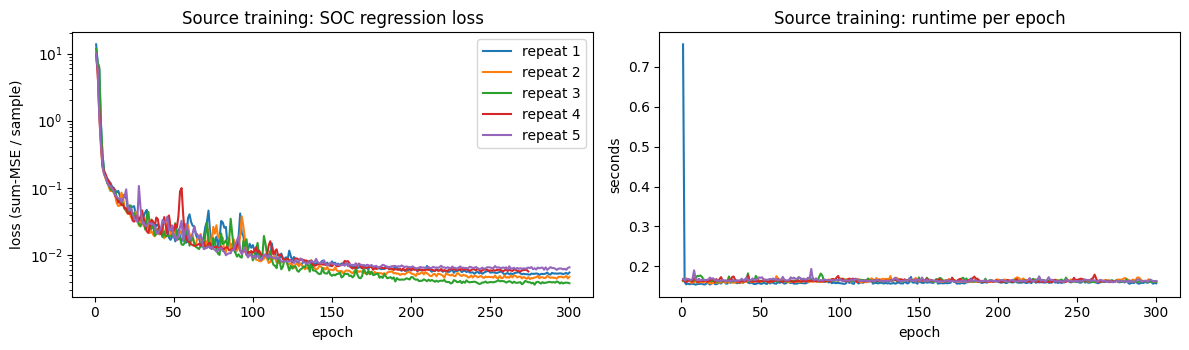

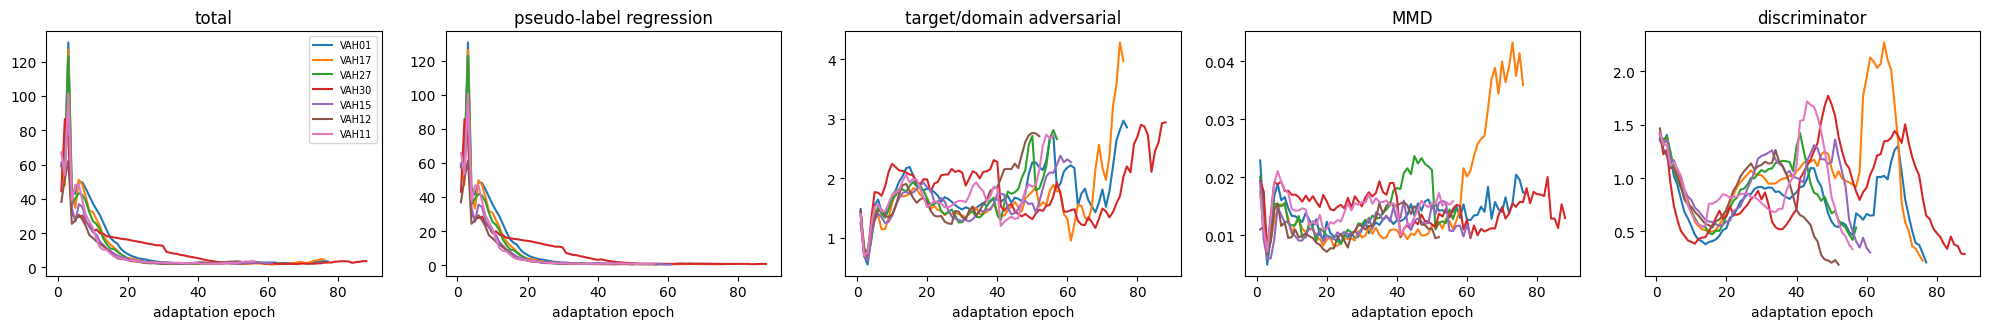

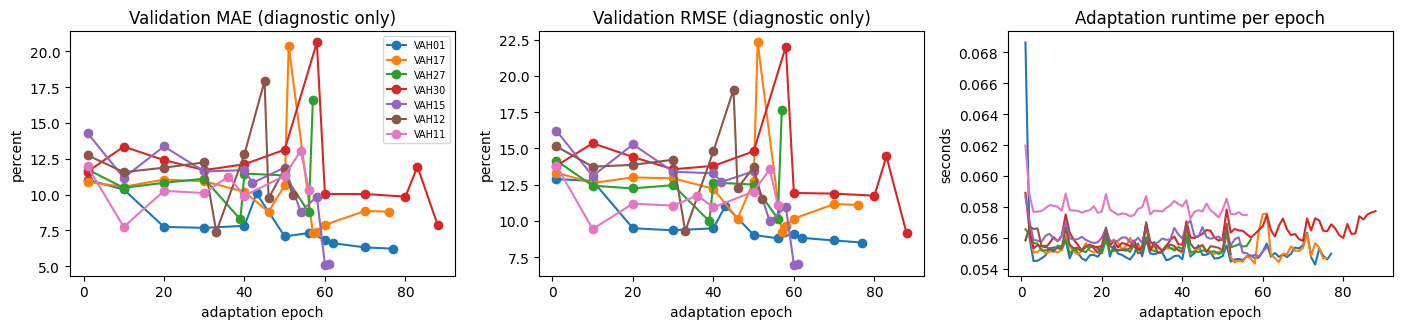

Pseudo-label selection (threshold 0.08), last adaptation epoch:


,pseudo_accepted_windows,pseudo_candidate_windows,pseudo_accepted_fraction
cell_id,,,
VAH01,77,100,0.770
VAH17,77,100,0.770
VAH27,77,100,0.770
VAH30,77,100,0.770
VAH15,79,106,0.745
VAH12,77,98,0.786
VAH11,85,100,0.850


In [34]:
if not RESULTS_READY:
    print('No completed run found at the output root; set RUN_EXPERIMENT = True and run Section 6 first.')
else:
    import matplotlib.pyplot as plt

    history = pd.read_csv(OUTPUT_ROOT / "training_history.csv")
    source_history = pd.read_csv(OUTPUT_ROOT / "source_training_history.csv")
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    for repeat, part in source_history.groupby("repeat"):
        axes[0].plot(part["epoch"], part["source_soc_regression_loss"], label=f"repeat {repeat}")
        axes[1].plot(part["epoch"], part["runtime_seconds"], label=f"repeat {repeat}")
    axes[0].set(title="Source training: SOC regression loss", xlabel="epoch", ylabel="loss (sum-MSE / sample)", yscale="log")
    axes[1].set(title="Source training: runtime per epoch", xlabel="epoch", ylabel="seconds")
    axes[0].legend(); plt.tight_layout(); plt.show()

    loss_cols = [("total_loss", "total"), ("pseudo_label_loss", "pseudo-label regression"),
                 ("adversarial_loss", "target/domain adversarial"), ("mmd_loss", "MMD"), ("discriminator_loss", "discriminator")]
    if history.empty:
        print("No adaptation epochs recorded (all cells were no-ops).")
    else:
        fig, axes = plt.subplots(1, len(loss_cols), figsize=(4 * len(loss_cols), 3.4))
        for ax, (col, title) in zip(axes, loss_cols):
            for cell in CELLS:
                part = history[history["cell_id"] == cell].groupby("epoch")[col].mean()
                if len(part):
                    ax.plot(part.index, part.values, label=cell)
            ax.set(title=title, xlabel="adaptation epoch")
        axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

        probed = history[history["validation_evaluated"].astype(bool)]
        fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
        for cell in CELLS:
            part = probed[probed["cell_id"] == cell].groupby("epoch")
            if len(part):
                axes[0].plot(part["validation_overall_mae"].mean(), marker="o", label=cell)
                axes[1].plot(part["validation_overall_rmse"].mean(), marker="o", label=cell)
            run = history[history["cell_id"] == cell].groupby("epoch")["runtime_seconds"].mean()
            if len(run):
                axes[2].plot(run.index, run.values, label=cell)
        axes[0].set(title="Validation MAE (diagnostic only)", xlabel="adaptation epoch", ylabel="percent")
        axes[1].set(title="Validation RMSE (diagnostic only)", xlabel="adaptation epoch", ylabel="percent")
        axes[2].set(title="Adaptation runtime per epoch", xlabel="adaptation epoch", ylabel="seconds")
        axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()
        accepted = history.groupby("cell_id")[["pseudo_accepted_windows", "pseudo_candidate_windows", "pseudo_accepted_fraction"]].last().reindex(CELLS)
        print("Pseudo-label selection (threshold 0.08), last adaptation epoch:")
        display(accepted.round(3))


## 12. Computational-cost summary

*Source only* costs only the source training; *TATN* costs source training **plus** adaptation. Training-only seconds are the sum of per-epoch `runtime_seconds`; wall-clock additionally includes pseudo-label generation and the diagnostic validation probe. Totals are cumulative over resumed invocations.

In [35]:
if not RESULTS_READY:
    print('No completed run found at the output root; set RUN_EXPERIMENT = True and run Section 6 first.')
else:
    runtime = META["runtime"]
    cost = META["compute_cost"]
    rows = [
        ("device", cost["device"]), ("GPU", cost["gpu_name"]), ("torch", cost["torch_version"]),
        ("source training (training-only s, all repeats)", round(runtime["total_source_training_seconds"], 2)),
        ("adaptation (training-only s, all repeats x cells)", round(runtime["total_adaptation_training_seconds"], 2)),
        ("adaptation wall-clock (s, incl. pseudo-labels + validation probe)", round(runtime["total_adaptation_wall_clock_seconds"], 2)),
        ("this invocation wall-clock (s)", round(runtime["invocation_wall_clock_seconds"], 2)),
        ("cumulative wall-clock (s)", round(META["cumulative_wall_clock_seconds"], 2)),
        ("peak CUDA memory (MB)", cost["peak_cuda_memory_allocated_mb"]),
    ]
    display(pd.DataFrame(rows, columns=["item", "value"]))
    display(pd.Series(cost["parameter_counts"], name="parameters").to_frame())
    src_epoch = source_history.groupby("repeat")["runtime_seconds"].agg(["count", "sum", "mean"]).rename(columns={"count": "epochs", "sum": "total_s", "mean": "s_per_epoch"})
    print("Source training per repeat:"); display(src_epoch.round(3))
    if len(history):
        ad = history.groupby(["repeat", "cell_id"])["runtime_seconds"].agg(["count", "sum", "mean"]).rename(columns={"count": "epochs", "sum": "total_s", "mean": "s_per_epoch"})
        print("Adaptation per repeat x cell:"); display(ad.round(3))
    total_tatn = runtime["total_source_training_seconds"] + runtime["total_adaptation_training_seconds"]
    print(f"TATN end-to-end training-only time (source + adaptation): {total_tatn:.1f} s; Source only: {runtime['total_source_training_seconds']:.1f} s")


,item,value
0,device,cuda
1,GPU,NVIDIA L4
2,torch,2.11.0+cu130
3,"source training (training-only s, all repeats)",241.93
4,"adaptation (training-only s, all repeats x cells)",104.66
5,"adaptation wall-clock (s, incl. pseudo-labels ...",209.13
6,this invocation wall-clock (s),760.65
7,cumulative wall-clock (s),760.65
8,peak CUDA memory (MB),1279.509277


,parameters
source_extractor,922880
predictor,16641
target_extractor,922880
discriminator,11521
total,1873922
trainable_in_adaptation,934401
trainable_in_source_training,939521


Source training per repeat:


,epochs,total_s,s_per_epoch
repeat,,,
1,300,48.621,0.162
2,300,49.221,0.164
3,300,49.404,0.165
4,274,45.079,0.165
5,300,49.609,0.165


Adaptation per repeat x cell:


epochs  total_s  s_per_epoch
repeat cell_id                              
1      VAH01        56    3.117        0.056
       VAH11        36    2.013        0.056
       VAH12        46    2.518        0.055
       VAH15        42    2.368        0.056
       VAH17        58    3.173        0.055
       VAH27        50    2.726        0.055
       VAH30        30    1.644        0.055
2      VAH01        56    3.091        0.055
       VAH11        56    3.237        0.058
       VAH12        50    2.757        0.055
       VAH15        61    3.352        0.055
       VAH17        57    3.155        0.055
       VAH27        39    2.147        0.055
       VAH30        40    2.239        0.056
3      VAH01        62    3.425        0.055
       VAH11        40    2.431        0.061
       VAH12        33    1.839        0.056
       VAH15        54    3.098        0.057
       VAH17        46    2.566        0.056
       VAH27        56    3.132        0.056
       VAH30        88    5.117        0.058
4      VAH01        43    2.363        0.055
       VAH11        54    3.117        0.058
       VAH12        45    2.574        0.057
       VAH15        50    2.802        0.056
       VAH17        51    2.858        0.056
       VAH27        57    3.184        0.056
       VAH30        58    3.190        0.055
5      VAH01        77    4.244        0.055
       VAH11        56    3.225        0.058
       VAH12        52    2.867        0.055
       VAH15        58    3.236        0.056
       VAH17        76    4.193        0.055
       VAH27        56    3.093        0.055
       VAH30        83    4.570        0.055

TATN end-to-end training-only time (source + adaptation): 346.6 s; Source only: 241.9 s


## 13. Limitations and provenance report

In [36]:
if not RESULTS_READY:
    print('No completed run found at the output root; set RUN_EXPERIMENT = True and run Section 6 first.')
else:
    print("git commit:", META["git_commit"], "| dirty:", META["git_dirty"])
    print("manifest:", META["cmu_manifest_path"], META["cmu_manifest_sha256"][:16] + "...")
    print("source kind:", META["source_kind"], "| scenario:", META["scenario"], "| tensor layout:", META["tensor_layout"])
    print("source checkpoints:"); display(pd.DataFrame(META["source_checkpoints"])[["repeat", "path", "sha256", "trained_this_run", "independent_per_repeat"]])
    print("repeats:", META["repeats"], "| repeat seeds:", META["repeat_seeds"], "| evaluation unit:", META["evaluation_unit"])
    print("phase mapping:", META["phase_mapping_version"], META["phase_mapping_sha256"][:16] + "...")
    print("reference check:", META["protocol_verification"]["reference_check"])
    print("formal_benchmark_eligible:", META["formal_benchmark_eligible"])
    if META["formal_benchmark_ineligibility_reasons"]:
        print("  not eligible because:", "; ".join(META["formal_benchmark_ineligibility_reasons"]))
    print()
    print("Limitations")
    for line in [
        "CMU SOC is a development proxy reference (capacity-based estimate), not laboratory ground truth; it is used only post-hoc and in the diagnostic validation probe.",
        "TATN is unsupervised here: when no stable pseudo-label segment exists a cell is a recorded no-op (TATN == Source only, 0 epochs) rather than a failure.",
        "Validation-probe curves are diagnostic only; they were not used for early stopping, checkpoint selection, pseudo-label thresholds or hyper-parameters.",
        "Standard deviations are NaN with one repeat (screening); report mean ± std only from the 5-repeat formal run.",
        "The paper states no epoch budget; the repository's verified caps (300 source / 150 adaptation, with early stopping) are used.",
        "The full-mission diagnostic is derived from the same held-out test missions (CMU mission candidates are flight-only), so it equals the primary test unless an unmapped Ns appears.",
        "The official pre-25.pt variant (if run) is a separate diagnostic and is never averaged with the primary source.",
        "Historical August TATN outputs use an older schema/protocol; they are not comparable and are neither resumed nor overwritten.",
        "Do not describe TATN as formally complete until a formal run reports formal_benchmark_eligible = true.",
    ]:
        print("-", line)


git commit: 6fb502753f76e76c71a6f9eccb65dc0f863f9de2 | dirty: False
manifest: /content/battery-soc-transfer-benchmark/data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv 0e3de73a6ae76f6a...
source kind: trained | scenario: unsupervised | tensor layout: paper
source checkpoints:


,repeat,path,sha256,trained_this_run,independent_per_repeat
0,1,/content/drive/MyDrive/battery_soc_benchmark/o...,ce58592b49e9c8825a355fc4fa0cffa46c0385b6e70d96...,True,True
1,2,/content/drive/MyDrive/battery_soc_benchmark/o...,d1aec4cd65889b1e36f1362db110cdc837daeedf9bbc9a...,True,True
2,3,/content/drive/MyDrive/battery_soc_benchmark/o...,65141bc08fb21493e463e3fff73f1bc098715a2c03d8c3...,True,True
3,4,/content/drive/MyDrive/battery_soc_benchmark/o...,5f4d15f0dca5a7b70c807a8da01f606fa406c739411380...,True,True
4,5,/content/drive/MyDrive/battery_soc_benchmark/o...,d305f5a3b61e6d1d5f665608ed237be6ad9c7d688373d8...,True,True


repeats: 5 | repeat seeds: [100, 1100, 2100, 3100, 4100] | evaluation unit: all_timesteps
phase mapping: cmu_evtol.ns_phase_labeling_v1.NS_MISSION_PHASE_MAP 3e2ee06938a95e3c...
reference check: passed
formal_benchmark_eligible: True

Limitations
- CMU SOC is a development proxy reference (capacity-based estimate), not laboratory ground truth; it is used only post-hoc and in the diagnostic validation probe.
- TATN is unsupervised here: when no stable pseudo-label segment exists a cell is a recorded no-op (TATN == Source only, 0 epochs) rather than a failure.
- Validation-probe curves are diagnostic only; they were not used for early stopping, checkpoint selection, pseudo-label thresholds or hyper-parameters.
- Standard deviations are NaN with one repeat (screening); report mean ± std only from the 5-repeat formal run.
- The paper states no epoch budget; the repository's verified caps (300 source / 150 adaptation, with early stopping) are used.
- The full-mission diagnostic is derived fr